# KinyaNews AI — reproducible Kinyarwanda classification study
Execute in order from the project root. Outputs in this notebook must be generated, not invented.

## 1. Dataset audit and leakage precautions
Use official KINNEWS labels. Downloaded corpus is expected. If the dataset loader is unavailable, run `python -m src.prepare_data --local-csv <official.csv>` in a terminal.
A local `data/official_kinnews.csv` is used when available. Its labels must be the official English names or zero-based Hugging Face IDs; original one-based CSV labels must be converted first. The original train/test files are pooled and re-split after cleaning, so these results are not directly comparable to the paper’s published benchmark split.


In [1]:
from pathlib import Path
import os, sys
# Support opening the notebook from either the root or notebooks directory.
ROOT = Path.cwd() if Path("src").is_dir() else Path.cwd().parent
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.prepare_data import prepare
local_corpus = Path("data/official_kinnews.csv")
audit = prepare(local_csv=local_corpus if local_corpus.exists() else None)
audit


{'raw_rows': 21268,
 'valid_length_rows': 21268,
 'conflicting_unique_texts': 159,
 'duplicate_rows_removed': 8891,
 'unique_rows': 10924,
 'source': 'data/official_kinnews.csv',
 'seed': 42,
 'splits': {'train': 7646, 'val': 1639, 'test': 1639},
 'label_counts': {'politics': 2082,
  'entertainment': 1769,
  'sport': 1718,
  'health': 1355,
  'economy': 1283,
  'relationship': 757,
  'religion': 701,
  'technology': 253,
  'history': 229,
  'culture': 215,
  'education': 186,
  'environment': 138,
  'fashion': 129,
  'tourism': 109},
 'exact_cross_split_overlap': 0,
 'warning': 'Exact duplicates checked; semantic near-duplicates and sources may still cause leakage.'}

## 2. Exploratory data analysis

Sizes 7646 1639 1639
label
politics         1457
entertainment    1238
sport            1203
health            948
economy           898
relationship      530
religion          491
technology        177
history           160
culture           151
education         130
environment        97
fashion            90
tourism            76
Name: count, dtype: int64


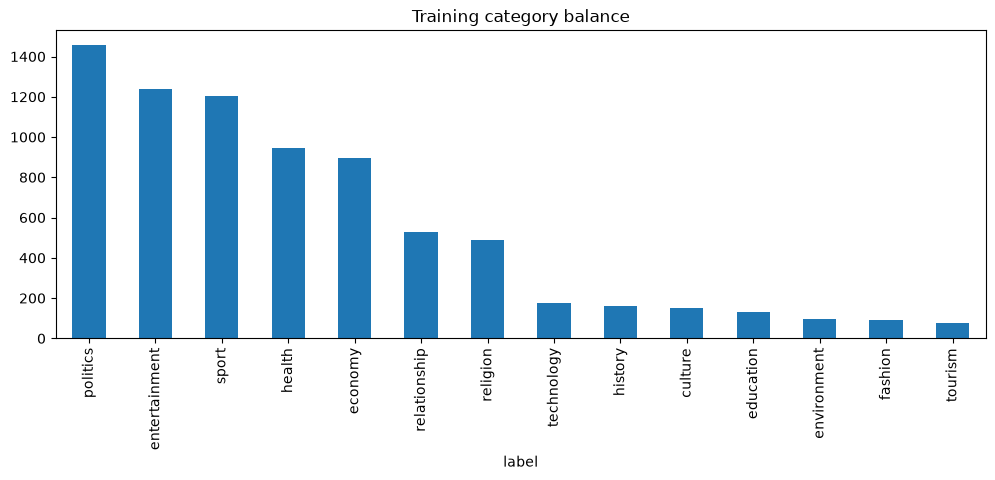

In [2]:
import pandas as pd, matplotlib.pyplot as plt
train = pd.read_csv("data/train.csv")
valid = pd.read_csv("data/val.csv")
test = pd.read_csv("data/test.csv")
print("Sizes",len(train),len(valid),len(test))
print(train.label.value_counts())
train.label.value_counts().plot.bar(figsize=(12,4),title="Training category balance"); plt.show()

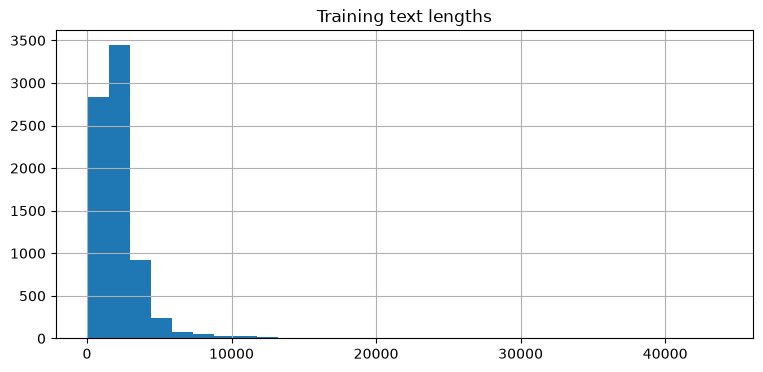

,text,label
0,menya amateka bakobwa batanze umusanzu ukomeye...,history
1,ibimenyetso bizakwereka mukundana agushakaho u...,relationship
2,umuyobozi w’umudugudu agiye kuryozwa amafarang...,health
3,mu mafoto uko byari byifashe hatora miss rusiz...,entertainment
4,uko abanyarwanda bitwaye tour du rwanda birata...,sport


In [3]:
train["length"] = train.text.str.len()
train.length.hist(bins=30,figsize=(9,4)); plt.title("Training text lengths");plt.show()
train[["text","label"]].head(5)

## 3. Validation experiments
The majority dummy is a sanity-check; word and character n-gram models are evaluated on the *same* validation data.

In [4]:
from src.train_baseline import experiments
rows = experiments()
pd.DataFrame(rows)

Training majority_dummy...


majority_dummy: validation macro F1=0.02285


Training tfidf_logreg...


tfidf_logreg: validation macro F1=0.71840


Training tfidf_linear_svm...


tfidf_linear_svm: validation macro F1=0.71710


Training tfidf_char_svm...


tfidf_char_svm: validation macro F1=0.70543


      experiment  validation_accuracy  validation_macro_f1  train_seconds  train_size  val_size  seed
    tfidf_logreg              0.79378              0.71840         13.329        7646      1639    42
tfidf_linear_svm              0.80293              0.71710          8.596        7646      1639    42
  tfidf_char_svm              0.79378              0.70543         41.345        7646      1639    42
  majority_dummy              0.19036              0.02285          0.008        7646      1639    42


,experiment,validation_accuracy,validation_macro_f1,train_seconds,train_size,val_size,seed
0,tfidf_logreg,0.79378,0.71840,13.329,7646,1639,42
1,tfidf_linear_svm,0.80293,0.71710,8.596,7646,1639,42
2,tfidf_char_svm,0.79378,0.70543,41.345,7646,1639,42
3,majority_dummy,0.19036,0.02285,0.008,7646,1639,42


## 4. Held-out test evaluation
Do this *after* choosing the final model from validation results. Never tune hyperparameters using the test scores.

In [5]:
from src.evaluate import evaluate
metrics = evaluate()
metrics

{
  "test_accuracy": 0.7748627211714461,
  "test_macro_f1": 0.7250922417435397,
  "test_samples": 1639
}


{'test_accuracy': 0.7748627211714461,
 'test_macro_f1': 0.7250922417435397,
 'test_samples': 1639}

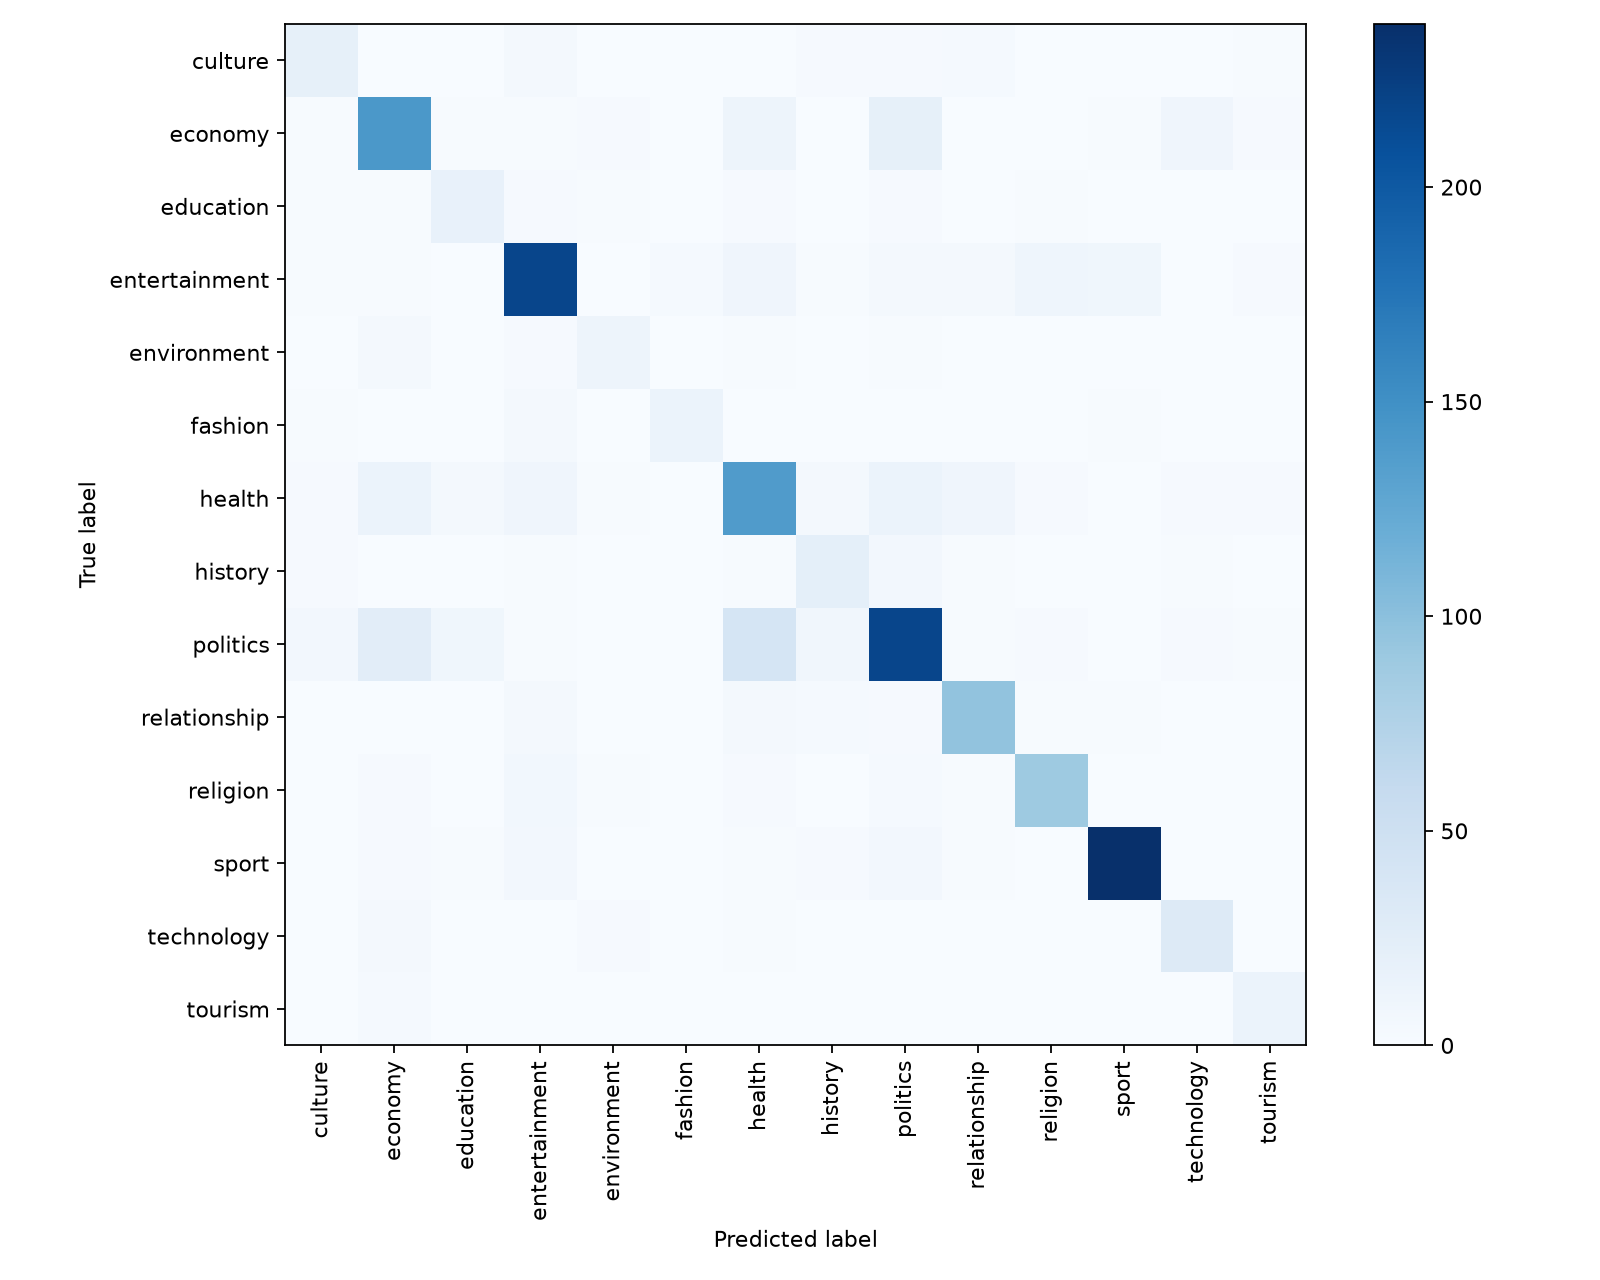

,Unnamed: 0,precision,recall,f1-score,support
0,culture,0.588235,0.625000,0.606061,32.000000
1,economy,0.713568,0.739583,0.726343,192.000000
2,education,0.545455,0.642857,0.590164,28.000000
3,entertainment,0.835249,0.822642,0.828897,265.000000
4,environment,0.631579,0.571429,0.600000,21.000000
5,fashion,0.823529,0.700000,0.756757,20.000000
6,health,0.647887,0.676471,0.661871,204.000000
7,history,0.511628,0.647059,0.571429,34.000000
8,politics,0.781362,0.696486,0.736486,313.000000
9,relationship,0.820513,0.849558,0.834783,113.000000


In [6]:
from IPython.display import display,Image
display(Image(filename="results/confusion_matrix.png"))
display(pd.read_csv("results/classification_report.csv"))

## 5. Error analysis
Read incorrect examples below. Identify ambiguous subjects, short articles, class confusion, vocabulary variations and possible annotation problems. Write your own real observations.

In [7]:
examples=pd.read_csv("results/per_example_predictions.csv")
print("Errors",(~examples.correct).sum())
display(examples.loc[~examples.correct,["text","label","prediction"]].head(15))
display(examples.loc[examples.correct,["text","label","prediction"]].head(10))

Errors 369


,text,label,prediction
0,perezida kagame yakiriye abaganga rotary abash...,economy,health
2,perezida kagame yagize avuga bwiyongere bw’ing...,economy,politics
3,rubavu abagabo barasiwe murenge rubavu bagerag...,health,politics
4,abaturage bakoreye rwiyemezamirimo witwa abatu...,environment,economy
9,irene uwoya uzwi oprah yahishuye yikundira aba...,entertainment,relationship
10,gishwati residents decry delayed land compensa...,environment,entertainment
11,rwamagana abapfakazi n’inshike jenoside baraby...,health,economy
13,ibintu gandhi yemeraga byahindura isi mahatma ...,history,relationship
20,abarimo sandrine isheja bruce melodie arthur b...,entertainment,health
43,kigali hibazwa impamvu hatihutiwe gukemura ibu...,health,economy


,text,label,prediction
1,uburanga umutesi denise umwe bakobwa bahabwa a...,entertainment,entertainment
5,abanyamadini barasabwa gukomeza kwamagana abay...,religion,religion
6,kwibuka abakinnyi arsenal bifatanyije n’abanya...,sport,sport
7,iyi niyo myaka nyayo y’abagore baryohererwamo ...,relationship,relationship
8,perezida madagascar yavuzeko bavumbuye umuti c...,health,health
12,abikorera bakomeje gushyigikirwahari umushinga...,economy,economy
14,ndererehe yafatiwe cyuho atetse kanyanga umuny...,politics,politics
15,arsenal yirukanye unai emery n’abari bamwungir...,sport,sport
16,fda yaburiye abanyarwanda kudakoresha chroloqu...,health,health
17,kera kabaye radio itsinda goodlife agiye gukor...,entertainment,entertainment


## 6. Optional Transformer comparison (separate GPU run)
Command: `python -m src.train_transformer --model xlm-roberta-base --epochs 2`. Include validation results only when completed; do not use this model in production until its actual inference service is deployed.

## 7. Conclusions

Logistic Regression won on validation macro F1 (0.71840), ahead of word Linear SVM (0.71710) and character Linear SVM (0.70543). Its held-out test accuracy is **77.49%**, with **0.72509 macro F1** across 1,639 articles. These are measured outputs from this run.

Sport had the strongest class F1 (0.93886), while history (0.57143) and education (0.59016) were weaker. Politics → health was the most frequent confusion (40 articles). Minority categories have small test supports, so their estimates are less stable.

Cleaning retained 10,924 of the original 21,268 articles. There is zero exact cross-split overlap, but semantic and source overlap remain unaudited. The pooled, deduplicated random split is not the published benchmark split. The optional transformer experiment was not run.

All three trained artifacts were saved. The next cell checks their reloads and validates the app's selected classifier. Its size is about 7.1 MB; platform packaging and public deployment remain separate checks. Full results are in `results/run_summary.md`.


In [8]:
import hashlib, json, joblib
import numpy as np
from sklearn.metrics import f1_score
from app import app, get_model, get_metadata
metadata = json.loads(Path("models/metadata.json").read_text())
checks = []
for row in rows:
    if row["experiment"] == "majority_dummy":
        continue
    path = Path("models") / (row["experiment"] + ".joblib")
    loaded = joblib.load(path)
    predictions = loaded.predict(valid.text)
    score = f1_score(valid.label, predictions, average="macro", zero_division=0)
    assert round(float(score), 5) == row["validation_macro_f1"]
    assert set(loaded.classes_) == set(train.label.unique())
    checks.append({"model": row["experiment"], "bytes": path.stat().st_size,
                   "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
                   "validation_macro_f1": float(score), "reload_verified": True})
deployed = joblib.load("models/classifier.joblib")
selected = joblib.load(Path("models") / (metadata["selected_model"] + ".joblib"))
assert np.array_equal(deployed.predict(valid.text), selected.predict(valid.text))
get_model.cache_clear()
get_metadata.cache_clear()
client = app.test_client()
assert client.get("/").status_code == 200
health = client.get("/health")
assert health.status_code == 200 and health.get_json()["model_loaded"]
sample = test.loc[test.text.str.len().between(30, 10000)].iloc[0]
response = client.post("/api/predict", json={"text": sample.text})
assert response.status_code == 200
assert response.get_json()["label"] == deployed.predict([sample.text])[0]
verification = {"artifacts": checks, "selected_model": metadata["selected_model"],
                "deployment_matches_selected": True, "health": health.get_json(),
                "sample_expected": sample.label, "sample_response": response.get_json()}
Path("results/model_verification.json").write_text(json.dumps(verification, indent=2))
display(pd.DataFrame(checks))
print("Selected model:", metadata["selected_model"])
print(f"Held-out accuracy: {metrics['test_accuracy']:.2%}; macro F1: {metrics['test_macro_f1']:.4f}")
print("API verification:", health.get_json(), response.get_json())
print("Limitations: random article split; semantic/source overlap is not audited; scores are not the original benchmark.")


,model,bytes,sha256,validation_macro_f1,reload_verified
0,tfidf_logreg,7128638,35cc33657080ca9a64529a821c033aee12d6afd3dcda7e...,0.718397,True
1,tfidf_linear_svm,6467433,d48b194ecb3f8bd5a29de45e9e5d9749fce8b00a2192eb...,0.717096,True
2,tfidf_char_svm,7002078,28e54a286a16c361b2cbcba7ef748986e04d73326a3d39...,0.705428,True


Selected model: tfidf_logreg
Held-out accuracy: 77.49%; macro F1: 0.7251
API verification: {'model': 'tfidf_logreg', 'model_loaded': True, 'status': 'ready'} {'label': 'health', 'label_kin': 'Ubuzima', 'model': 'tfidf_logreg', 'top_categories': [{'label': 'health', 'label_kin': 'Ubuzima', 'score': 0.3346}, {'label': 'politics', 'label_kin': 'Politiki', 'score': 0.2341}, {'label': 'economy', 'label_kin': 'Ubukungu', 'score': 0.088}], 'warning': 'Category prediction is not fact-checking. Confidence, if shown, is not guaranteed calibration.'}
Limitations: random article split; semantic/source overlap is not audited; scores are not the original benchmark.


## 8. Extended local analysis

Generated analysis artifacts are reproduced with `python -m src.analyze_results`; the selected model is unchanged. These later exploratory ablations are distinct from the original model-selection comparison.

# Analysis of measured results

## Questions and original model comparison

1. Does learning lexical features beat a majority-class sanity baseline? Validation macro F1 rises from 0.02285 to 0.71840 with word TF-IDF plus balanced Logistic Regression. The majority baseline's 19.04% accuracy illustrates class imbalance; it is not a useful classifier for minority topics.
2. Does changing the classifier help with the same word features? Linear SVM achieves 80.29% accuracy versus Logistic Regression's 79.38%, but slightly lower macro F1 (0.71710 versus 0.71840). Macro F1 gives each category equal weight, so it was the prespecified selection criterion.
3. Do character features help? Character 3–5 grams with SVM yield 0.70543 macro F1. Character features can represent recurring subword forms and spelling patterns without a morphological analyzer. On this fixed feature budget and split they did not beat word features. This result does not prove they are generally unsuitable for Kinyarwanda.

The original Logistic Regression winner stays frozen. Scores are from the pooled, deduplicated split, not the published benchmark. No Transformer results are claimed.

## Additional validation-only ablations

All use the same training and validation data, seed 42, min_df=2, max_features=60,000, sublinear TF and maximum 1,000 optimizer iterations. Only the listed factor changes from the selected balanced word (1,2)-gram Logistic Regression with C=1.

| Configuration | Accuracy | Macro F1 | Interpretation |
| --- | ---: | ---: | --- |
| Original frozen configuration | 0.79378 | 0.71840 | Original model-selection winner |
| Unigrams only | 0.79073 | 0.71942 | Slightly higher macro F1; bigrams are not clearly beneficial here |
| No class weighting | 0.76693 | 0.55462 | Large macro-F1 loss supports balancing classes in this setting |
| C=0.1 | 0.73703 | 0.66774 | Stronger regularization loses useful discrimination |
| C=10 | 0.80232 | 0.70728 | Higher accuracy but lower macro F1; accuracy alone obscures minority performance |

All four fits finished below the iteration limit. Unigrams narrowly exceed the original winner in this later exploration. The deployed model is correctly described as the winner of the **original three-candidate comparison**, not the best of every configuration ever tested. Because test results were already inspected before this extension, we do not switch models or evaluate new ablations on that test set. A future prespecified comparison should use a fresh untouched holdout or nested cross-validation. This prevents exploratory analysis from becoming hidden test-driven model selection.

## Evaluation and uncertainty

The frozen model achieves 77.486% test accuracy, macro precision 0.71435, macro recall 0.74172 and macro F1 0.72509. Weighted F1 is 0.77620. Accuracy is the fraction of correct labels; precision measures how often a predicted category is right; recall measures how many true members of a category were found. F1 is the harmonic mean of precision and recall, computed per category before macro averaging. Macro F1 is useful here because class counts are highly unequal.

A seeded 1,000-replicate class-stratified bootstrap gives test macro F1 a percentile 95% interval of [0.68869, 0.75660]. The paired validation macro-F1 difference (Logistic Regression minus word SVM) has interval [-0.02073, 0.02644]. The interval crosses zero, so the small observed advantage is not persuasive evidence of stable superiority. These intervals condition on this model and split, preserve observed class counts, and do not account for training-seed or source variation.

Sport has F1 0.93886 on 257 examples. History and education have F1 0.57143 and 0.59016 on only 34 and 28 examples. Small support limits precision of minority-class estimates; the observed imbalance is a plausible contributor, not proof of the cause of every error.

## Representative examples and model explanations

Rows are zero-based positions in `data/test.csv`. Retrieve their full text locally; `results/explained_examples.json` records SHA-256 text identifiers and feature contributions. Examples are deliberately selected for interpretation, not a random sample of errors. Contributions are feature value multiplied by the coefficient for the predicted class; they explain part of the linear score, not calibrated confidence, causality, or the entire comparison with other classes. Intercepts and competing-class coefficients also affect the final decision.

| Test row | Supplied label → prediction | Observation and plausible explanation |
| --- | --- | --- |
| 1 | entertainment → entertainment | A Miss Rwanda contestant article. `miss`, `nyampinga`, and `miss rwanda` provide strong positive evidence, matching the entertainment topic. |
| 0 | economy → health | The article discusses doctors, treatment and hospitals. `abaganga`, `abarwayi`, and `bitaro` contribute strongly toward health. The supplied economy label may reflect broad editorial taxonomy or an annotation issue; independent adjudication is needed before calling it wrong. |
| 2 | economy → politics | An article on gorilla conservation prominently names the president. `perezida`, `kagame`, and `perezida kagame` contribute toward politics. Entity shortcuts can override the economic/conservation framing. |
| 4 | environment → economy | Tree-planting workers discuss unpaid wages. `amafaranga`, `rwiyemezamirimo`, and payment vocabulary favor economy despite the environmental activity. A single label compresses a multi-topic story. |
| 9 | entertainment → relationship | A celebrity discusses partner preferences. Romance vocabulary such as `urukundo`, `umugabo`, and `gukundana` favors relationship; celebrity context supports the supplied entertainment label. |
| 10 | environment → entertainment | The inspected article is English and concerns forest-related compensation. `the` is the largest positive entertainment contribution. This is a language-quality/domain-mismatch example and a lexical shortcut, not evidence that the environmental content is entertainment. |
| 13 | history → relationship | A Gandhi article mixes historical identity with advice about personal conduct. General advice vocabulary contributes toward relationship; bag-of-ngrams features do not explicitly represent historical framing. |

Across all 369 errors, the largest confusions are politics→health (40), politics→economy (25), economy→politics (20), health→economy (14), and health→politics (14). These counts show overlapping editorial topics; they do not establish one universal cause. No test labels were edited, and no individual English article was removed to improve reported scores.

## Data quality and leakage screen

Exact normalized text overlap is zero. A new nearest-training-article screen using frozen word TF-IDF cosine similarity flags 36 validation articles and 51 test articles at similarity ≥0.90; 22 validation and 42 test articles reach ≥0.95. Maximum similarities are 0.99794 and 0.99918. Thus exact deduplication alone leaves highly similar lexical content across splits. These are candidates for duplicated/reworked articles or shared templates, requiring manual review; they are not all confirmed duplicate events. Report this threat to validity prominently. A stronger future evaluation would group related articles and sources before splitting, then train and select models again with a fresh holdout.

Training article length has median 1,779 characters and maximum 43,898. Test accuracy is 0.76667 for 210 articles below 1,000 characters, 0.76844 for 1,166 at 1,000–2,999 characters, and 0.80769 for 260 at 3,000–10,000. These descriptive groups cannot establish that length causes correctness. Three articles exceed the API's 10,000-character input limit; all were classified correctly offline. Whole-corpus offline evaluation and the deployed input contract differ slightly and this must be disclosed.

## Practical limitations and next steps

Scores measure label agreement on one corpus and split. There is no user study, time-based drift evaluation, probability calibration, automatic language verification, or out-of-domain rejection. A news-trained model always chooses a known category for accepted inputs. First priorities for further research are auditing high-similarity pairs and language quality, independently reviewing ambiguous annotations, and testing grouped splits; then compare embeddings or neural models using a fresh evaluation design. More model complexity is not a substitute for trustworthy data evaluation.

The dataset paper and research code include established TF-IDF baselines, so our contribution is a reproducible local study and practical classifier rather than a claim to invent Kinyarwanda topic classification. Sources and implementation ownership are documented in `docs/DATA_AND_ATTRIBUTION.md`.
